In [4]:
import warnings
warnings.filterwarnings('ignore')

import requests
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix 
from datetime import datetime, timedelta


In [5]:
def eda_analysis(df):
    import matplotlib.pyplot as plt
    import seaborn as sns
    import numpy as np

    # Count plot for FloodOccurrence
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x='FloodOccurrence')
    plt.title('Flood Occurrence Count')
    plt.xlabel('Flood Occurrence')
    plt.ylabel('Count')
    plt.show()

    # Histogram of Rainfall
    plt.figure(figsize=(8, 4))
    sns.histplot(df['Rainfall_mm'], kde=True)
    plt.title('Distribution of Rainfall (mm)')
    plt.xlabel('Rainfall (mm)')
    plt.ylabel('Frequency')
    plt.show()

    # Box plot for Water Level
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df, y='WaterLevel_m')
    plt.title('Water Level (m) Box Plot')
    plt.ylabel('Water Level (m)')
    plt.show()

    # Correlation heatmap for numeric features
    numeric_df = df.select_dtypes(include=[np.number])
    if numeric_df.shape[1] >= 4:
        plt.figure(figsize=(8, 6))
        corr = numeric_df.corr()
        sns.heatmap(corr, annot=True, cmap='coolwarm')
        plt.title('Correlation Heatmap of Numeric Features')
        plt.show()

    # Pair plot for numeric features
    sns.pairplot(numeric_df)
    plt.show()

In [6]:
def get_weather_data(lat, lon):
    url = "https://api.open-meteo.com/v1/forecast"
    
    params = {
        "latitude": lat,
        "longitude": lon,
        "hourly": "precipitation,temperature_2m,relativehumidity_2m",
        "timezone": "Asia/Manila"
    }

    response = requests.get(url, params=params)
    data = response.json()

    hourly = data['hourly']

    rain = hourly['precipitation']
    temp = hourly['temperature_2m']
    humidity = hourly['relativehumidity_2m']

    rain_24h = sum(rain[:24])
    rain_48h = sum(rain[:48])
    rain_72h = sum(rain[:72])

    avg_temp = sum(temp[:24]) / 24
    avg_humidity = sum(humidity[:24]) / 24

    return rain_24h, rain_48h, rain_72h, avg_temp, avg_humidity

cities = {
    "Quezon City": (14.65, 121.03),
    "Manila": (14.60, 120.98),
    "Marikina": (14.65, 121.10),
    "Pasig": (14.58, 121.06),
}

In [7]:
def prepare_data(data):
  le =  LabelEncoder()
  data['Location'] = le.fit_transform(data['Location'])
  data['Month'] = pd.to_datetime(data['Date']).dt.month
  data['Day'] = pd.to_datetime(data['Date']).dt.day
  
  X = data[['Month','Day','Location','Rain_24h','Rain_48h','Rain_72h','WaterLevel_m','SoilMoisture_pct','Elevation_m']]
  y = data['FloodOccurrence']
  
  return X, y, le

In [8]:
def train_model(X, y, threshold=0.5):
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
  model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
  model.fit(X_train, y_train)

  y_pred = model.predict(X_test)
  
  y_prob = model.predict_proba(X_test)[:, 1]
  y_pred = (y_prob > threshold).astype(int)

  print("Recall:", recall_score(y_test, y_pred))
  print("Precision:", precision_score(y_test, y_pred))
  print("F1-Score:", f1_score(y_test, y_pred))
  print("ROC AUC:", roc_auc_score(y_test, y_prob))
  print("PR-AUC:", average_precision_score(y_test, y_prob))
  
  conf_matrix = confusion_matrix(y_test, y_pred)
  plt.figure(figsize=(6,4))
  sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
  plt.title('Confusion Matrix')
  plt.xlabel('Predicted')
  plt.ylabel('Actual')
  plt.show()

  return model


In [9]:
def regression_data(data, feature):
  X, y = [], []
  
  for i in range(len(data) - 1):
    X.append(data[feature].iloc[i])
    y.append(data[feature].iloc[i + 1])
    
  X = np.array(X).reshape(-1, 1)
  y = np.array(y)
  return X, y

In [10]:
def train_regression_model(X, y):
  model = RandomForestRegressor(n_estimators=100, random_state=42)
  model.fit(X, y)
  
  return model

In [11]:
from xml.parsers.expat import model


def predict_flood_risk(model, le, water_model, city_name, lat, lon):
    from datetime import datetime
    
    rain_24h, rain_48h, rain_72h, avg_temp, avg_humidity = get_weather_data(lat, lon)

    now = datetime.now()

    location_encoded = le.transform([city_name])[0]

    water_level = water_model.predict([[rain_24h]])[0]

    soil_moisture = avg_humidity * 0.8 + rain_24h * 0.2

    elevation_map = {
        "Manila": 5,
        "Marikina": 8,
        "Quezon City": 20,
        "Pasig": 8
    }
    elevation = elevation_map.get(city_name, 10)

    input_data = pd.DataFrame([{
        'Month': now.month,
        'Day': now.day,
        'Location': location_encoded,
        'Rain_24h': rain_24h,
        'Rain_48h': rain_48h,
        'Rain_72h': rain_72h,
        'WaterLevel_m': water_level,
        'SoilMoisture_pct': soil_moisture,
        'Elevation_m': elevation
    }])

    prediction = model.predict_proba(input_data)[0][1]

    return prediction

In [12]:
def display_flood_risks(model, le, water_model):
    for city, (lat, lon) in cities.items():
        try:
            risk = predict_flood_risk(model, le, water_model, city, lat, lon)

            if risk > 0.7:
                status = "HIGH FLOOD RISK"
            elif risk > 0.4:
                status = "MODERATE FLOOD RISK"
            else:
                status = "LOW FLOOD RISK"

            print(f"{city}: {status}")

        except Exception as e:
            print(f"{city}: Error - {e}")

Recall: 0.88
Precision: 1.0
F1-Score: 0.9361702127659575
ROC AUC: 1.0
PR-AUC: 1.0


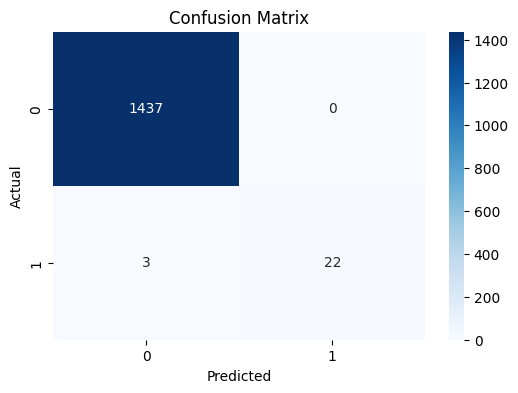

Quezon City: LOW FLOOD RISK
Manila: LOW FLOOD RISK
Marikina: LOW FLOOD RISK
Pasig: LOW FLOOD RISK
          Date  Location  Rainfall_mm  WaterLevel_m  SoilMoisture_pct  \
0     1/1/2016         3         12.0           0.5              15.3   
1     1/1/2016         1         10.6           1.8              23.2   
2     1/1/2016         0          5.7           0.5              15.6   
3     1/1/2016         2          3.7           0.5               5.0   
1466  1/1/2017         0         11.3           0.5              14.3   

      Elevation_m  FloodOccurrence  Rain_24h  Rain_48h  Rain_72h  Month  Day  
0              43                0      12.0       0.0       0.0      1    1  
1              15                0      10.6      22.6       0.0      1    1  
2               5                0       5.7      16.3      28.3      1    1  
3               5                0       3.7       9.4      20.0      1    1  
1466            5                0      11.3      15.0      20.7    

,Location,Rainfall_mm,WaterLevel_m,SoilMoisture_pct,Elevation_m,FloodOccurrence,Rain_24h,Rain_48h,Rain_72h,Month,Day
count,7308.00000,7308.000000,7308.000000,7308.000000,7308.000000,7308.000000,7308.000000,7308.000000,7308.000000,7308.000000,7308.000000
mean,1.50000,10.052874,1.266379,15.184989,17.000000,0.018062,10.052874,20.103708,30.152135,6.521073,15.735085
std,1.11811,7.101769,0.902239,5.994044,15.557414,0.133186,7.101769,10.082418,12.382220,3.449448,8.802994
min,0.00000,0.100000,0.500000,5.000000,5.000000,0.000000,0.100000,0.000000,0.000000,1.000000,1.000000
25%,0.75000,4.900000,0.500000,10.900000,5.000000,0.000000,4.900000,12.700000,21.200000,4.000000,8.000000
50%,1.50000,8.400000,1.000000,14.900000,10.000000,0.000000,8.400000,18.500000,28.350000,7.000000,16.000000
75%,2.25000,13.500000,1.800000,19.100000,22.000000,0.000000,13.500000,25.425000,37.200000,10.000000,23.000000
max,3.00000,52.700000,6.400000,39.700000,43.000000,1.000000,52.700000,76.300000,108.000000,12.000000,31.000000


In [13]:
df = pd.read_csv("dataset/flood-prediction.csv")
df = df.sort_values(by='Date')

df['Rain_24h'] = df['Rainfall_mm']
df['Rain_48h'] = df['Rainfall_mm'].rolling(2).sum()
df['Rain_72h'] = df['Rainfall_mm'].rolling(3).sum()

df = df.fillna(0)

X, y, le = prepare_data(df)
model = train_model(X, y, threshold=0.5)

X_reg, y_reg = regression_data(df, 'WaterLevel_m')
water_model = train_regression_model(X_reg, y_reg)

display_flood_risks(model, le, water_model)
print(df.head())
df.info()
df.describe()

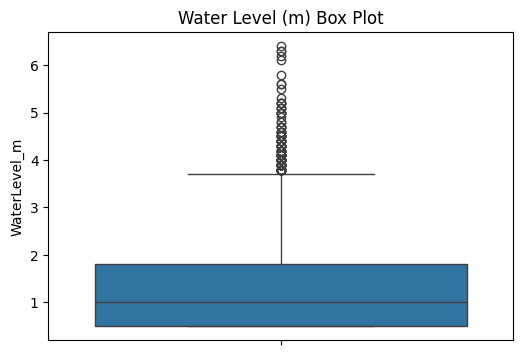

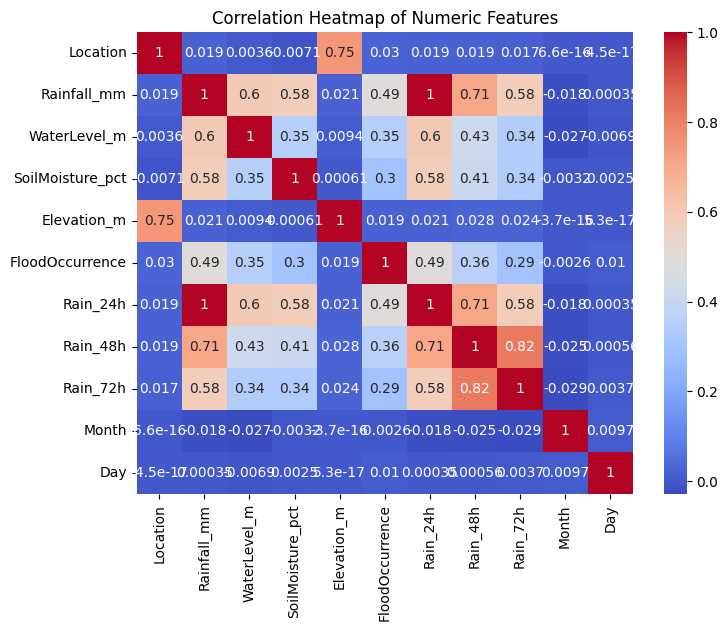

In [15]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, y="WaterLevel_m")
plt.title("Water Level (m) Box Plot")
plt.show()
numeric_df = df.select_dtypes(include=[np.number])
if numeric_df.shape[1] >= 4:
        plt.figure(figsize=(8, 6))
        corr = numeric_df.corr()
        sns.heatmap(corr, annot=True, cmap="coolwarm")
        plt.title("Correlation Heatmap of Numeric Features")
        plt.show()